<center><h1>Li_Ruifeng_HW3</h1></center>
<br>
<br>

Name: Ruifeng Li
<br>
Github Username: Lrf8182
<br>
USC ID: *(intentionally not published in this repository)*

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

The AReM data (Activity Recognition based on Multisensor data fusion) from the UCI repository is stored
in `AReM/` next to this notebook, with one sub-folder per activity. The notebook reads it with the relative
path `AReM/`, so it runs without edits as long as it is opened from the repository root.

Package imports

In [1]:
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = "AReM"
RANDOM_STATE = 552

Get the AReM Data Set

In [2]:
SIGNALS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def read_arem_file(path):
    """Read one AReM csv file.

    A few files need light cleaning: bending2/dataset4.csv is space-separated and
    some rows in cycling/dataset9.csv and cycling/dataset14.csv end with a trailing
    comma. Splitting each line on commas *or* whitespace handles all of them.
    """
    rows = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            values = [v for v in re.split(r"[,\s]+", line) if v]
            rows.append([float(v) for v in values[:7]])
    return pd.DataFrame(rows, columns=["time"] + SIGNALS)


def dataset_number(path):
    return int(re.search(r"dataset(\d+)", os.path.basename(path)).group(1))


instances = []
for activity in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, activity)
    if not os.path.isdir(folder):
        continue
    for path in sorted(glob.glob(f"{folder}/dataset*.csv"), key=dataset_number):
        k = dataset_number(path)
        frame = read_arem_file(path)
        instances.append({
            "activity": activity,
            "dataset": k,
            "n_rows": len(frame),
            "data": frame[SIGNALS].to_numpy(),
        })

print(f"Loaded {len(instances)} instances from {DATA_DIR}/")

lengths = pd.Series([inst["n_rows"] for inst in instances]).value_counts()
print("Rows per instance:", dict(lengths))

Loaded 88 instances from AReM/
Rows per instance: {480: np.int64(87), 479: np.int64(1)}


There are **88 instances** in the 7 activity folders. Every file holds 480 rows, except
`sitting/dataset8.csv`, which has 479. One value is missing out of 480, which is too little to matter for
the summary statistics, so that instance is kept as it is.

### (b) Test and Train Data

Datasets 1 and 2 of `bending1` and `bending2`, and datasets 1, 2 and 3 of every other folder, are the
test set. Everything else is the training set.

In [3]:
for inst in instances:
    n_test = 2 if inst["activity"].startswith("bending") else 3
    inst["split"] = "test" if inst["dataset"] <= n_test else "train"

split_table = (
    pd.DataFrame([{k: inst[k] for k in ("activity", "dataset", "split")} for inst in instances])
    .groupby(["activity", "split"]).size().unstack(fill_value=0)
)
split_table.loc["total"] = split_table.sum()
display(split_table)

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12
total,19,69


This gives **19 test instances and 69 training instances**.

### (c) Feature Extraction

#### i. Research

Time-domain features are computed directly from the raw samples, with no transform to the
frequency domain. Common ones in time-series classification include:

* **Location / central tendency:** mean, median, mode, trimmed mean.
* **Spread / dispersion:** standard deviation, variance, range (max − min), interquartile range,
  mean absolute deviation, coefficient of variation.
* **Order statistics:** minimum, maximum, first and third quartiles, other percentiles.
* **Shape of the distribution:** skewness, kurtosis.
* **Energy and amplitude:** root mean square (RMS), signal energy (sum of squares), peak-to-peak amplitude,
  crest factor (peak / RMS).
* **Change and complexity:** zero-crossing rate or mean-crossing rate, number of peaks, mean absolute first
  difference, slope of a linear trend, sample or approximate entropy.
* **Temporal dependence:** autocorrelation at chosen lags, Hjorth parameters (activity, mobility, complexity).

Activity-recognition work on accelerometer and RSS signals often uses the mean, standard deviation,
minimum, maximum, percentiles, RMS, and correlations between sensor channels.

#### ii. Extraction

For each of the 6 time series in each instance, the code below computes the minimum, maximum, mean, median,
standard deviation, first quartile and third quartile. That gives 6 × 7 = 42 features per instance. The
features are kept on their raw scale here. Standardizing them changes neither their ranking nor the spread
estimates in (iii), and the models in the next homework standardize inside the cross-validation loop.

In [4]:
FEATURE_FUNCS = {
    "min": lambda x: np.min(x, axis=0),
    "max": lambda x: np.max(x, axis=0),
    "mean": lambda x: np.mean(x, axis=0),
    "median": lambda x: np.median(x, axis=0),
    "std": lambda x: np.std(x, axis=0, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25, axis=0),
    "3rd_quart": lambda x: np.percentile(x, 75, axis=0),
}


def extract_features(l=1, stats=tuple(FEATURE_FUNCS)):
    """Time-domain features for every instance after cutting each series into l parts.

    Column names follow the assignment (min1, max1, ..., 3rd_quart6). With l > 1 the
    segment index is appended, e.g. mean2_seg3 is the mean of series 2 in segment 3.
    """
    rows = []
    for inst in instances:
        row = {}
        for s, segment in enumerate(np.array_split(inst["data"], l), start=1):
            values = {stat: FEATURE_FUNCS[stat](segment) for stat in stats}
            for j in range(len(SIGNALS)):
                for stat in stats:
                    name = f"{stat}{j + 1}" if l == 1 else f"{stat}{j + 1}_seg{s}"
                    row[name] = values[stat][j]
        rows.append(row)
    frame = pd.DataFrame(rows)
    frame.index = pd.RangeIndex(1, len(frame) + 1, name="Instance")
    return frame


meta = pd.DataFrame({
    "activity": [inst["activity"] for inst in instances],
    "dataset": [inst["dataset"] for inst in instances],
    "split": [inst["split"] for inst in instances],
}, index=pd.RangeIndex(1, len(instances) + 1, name="Instance"))

features = extract_features(l=1)
print("Feature matrix shape:", features.shape)
display(pd.concat([meta[["activity", "split"]], features.round(2)], axis=1))

Feature matrix shape: (88, 42)


,activity,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,test,37.25,45.00,40.62,40.50,1.48,39.25,42.00,0.0,1.30,0.36,0.43,0.32,0.00,0.50,4.00,29.50,19.04,19.25,4.46,16.00,23.25,0.0,7.23,0.83,0.50,0.97,0.00,1.12,27.25,38.25,34.31,35.00,2.19,33.00,36.00,0.00,1.92,0.57,0.43,0.58,0.00,1.30
2,bending1,test,38.00,45.67,42.81,42.50,1.44,42.00,43.67,0.0,1.22,0.37,0.47,0.29,0.00,0.50,2.00,29.50,20.10,21.00,3.89,19.00,22.25,0.0,5.76,0.88,0.50,1.05,0.00,1.14,27.67,38.50,33.02,33.00,2.00,32.00,34.50,0.00,3.11,0.57,0.43,0.60,0.00,1.30
3,bending1,train,35.00,47.40,43.95,44.33,1.56,43.00,45.00,0.0,1.70,0.43,0.47,0.34,0.00,0.50,6.50,29.75,22.12,23.00,3.03,19.75,24.00,0.0,4.44,0.50,0.43,0.55,0.00,0.83,29.00,38.50,35.59,36.00,2.00,35.36,36.50,0.00,1.79,0.49,0.43,0.51,0.00,0.94
4,bending1,train,33.00,47.75,42.18,43.50,3.67,39.15,45.00,0.0,3.00,0.70,0.50,0.63,0.00,1.12,8.50,30.00,22.18,23.00,3.81,20.50,24.37,0.0,5.15,0.99,0.83,0.95,0.43,1.30,20.00,38.67,33.49,35.00,3.85,30.46,36.33,0.00,2.18,0.61,0.50,0.52,0.00,1.00
5,bending1,train,33.00,45.75,41.68,41.75,2.24,41.33,42.75,0.0,2.83,0.54,0.50,0.41,0.43,0.71,3.00,28.25,19.01,19.12,4.09,16.50,22.06,0.0,6.42,0.84,0.50,0.93,0.43,1.12,23.67,37.50,29.86,30.00,2.41,28.46,31.25,0.00,1.79,0.38,0.43,0.39,0.00,0.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking,train,19.50,45.33,33.59,34.25,4.65,30.25,37.00,0.0,14.67,4.58,4.26,2.46,2.87,6.10,7.33,23.25,15.32,15.33,2.97,13.25,17.27,0.0,9.00,3.23,3.10,1.65,2.05,4.26,6.33,25.00,15.89,16.00,3.28,13.73,18.25,0.00,8.32,3.26,3.11,1.64,2.05,4.32
85,walking,train,19.75,45.50,34.32,35.25,4.75,31.00,38.00,0.0,13.47,4.46,3.90,2.60,2.49,5.97,6.25,22.25,15.21,15.25,2.71,13.50,17.00,0.0,9.00,3.28,3.11,1.50,2.17,4.39,6.25,23.25,15.55,15.75,3.12,13.50,17.75,0.00,9.67,3.43,3.20,1.73,2.16,4.56
86,walking,train,19.50,46.00,34.55,35.25,4.84,31.25,37.81,0.0,12.47,4.37,4.14,2.36,2.49,5.80,7.00,22.67,15.19,15.25,2.76,13.25,17.00,0.0,8.34,3.03,2.86,1.67,1.79,4.11,7.00,22.75,15.76,15.75,2.82,14.00,17.75,0.00,10.00,3.34,3.08,1.66,2.16,4.34


#### iii. Standard Deviation

The code estimates the standard deviation of each of the 42 features across all 88 instances. It then
resamples the 88 instances with replacement B = 2,000 times and recomputes the standard deviation each time.
The 5th and 95th percentiles of those 2,000 values form the 90% percentile bootstrap confidence interval.

In [5]:
B = 2000
rng = np.random.default_rng(RANDOM_STATE)
X = features.to_numpy()
n = X.shape[0]

boot_idx = rng.integers(0, n, size=(B, n))
boot_sd = np.stack([X[idx].std(axis=0, ddof=1) for idx in boot_idx])

sd_table = pd.DataFrame({
    "std": X.std(axis=0, ddof=1),
    "CI 5%": np.percentile(boot_sd, 5, axis=0),
    "CI 95%": np.percentile(boot_sd, 95, axis=0),
}, index=features.columns)
sd_table.index.name = "feature"
display(sd_table.round(3))

,std,CI 5%,CI 95%
feature,,,
min1,9.570,8.253,10.761
max1,4.394,3.363,5.270
mean1,5.336,4.695,5.913
median1,5.440,4.779,6.013
std1,1.772,1.565,1.947
1st_quart1,6.154,5.549,6.677
3rd_quart1,5.139,4.356,5.838
min2,0.000,0.000,0.000
max2,5.063,4.639,5.395


#### iv. Select Features

To choose the three most useful feature *types*, I measure how well each statistic separates the 7
activities on the training set. For each of the 42 features, the one-way ANOVA F statistic compares the
spread between activity means with the spread within activities, so a larger F means better separation.
The table averages F over the 6 time series for each statistic.

,mean,median,max
mean,368.2,307.4,900.2
3rd_quart,350.4,297.1,807.0
median,317.7,252.8,800.8
1st_quart,154.1,135.2,346.3
std,109.2,71.9,360.9
max,30.0,32.3,47.7
min,14.6,16.8,24.1


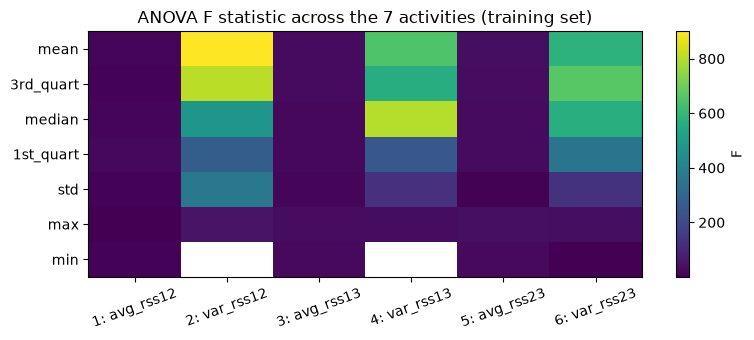

In [6]:
from scipy.stats import f_oneway

train = meta["split"] == "train"
f_scores = {}
for col in features.columns:
    groups = [features.loc[train & (meta["activity"] == a), col] for a in sorted(meta["activity"].unique())]
    f_scores[col] = f_oneway(*groups).statistic

f_scores = pd.Series(f_scores)
stat_of = f_scores.index.str.replace(r"\d+$", "", regex=True)
by_stat = f_scores.groupby(stat_of).agg(["mean", "median", "max"]).sort_values("mean", ascending=False)
display(by_stat.round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
f_matrix = pd.DataFrame({c: f_scores[c] for c in f_scores.index}, index=[0]).T
f_matrix["stat"] = stat_of
f_matrix["series"] = f_scores.index.str.extract(r"(\d+)$")[0].astype(int).to_numpy()
heat = f_matrix.pivot(index="stat", columns="series", values=0).loc[by_stat.index]
im = ax.imshow(heat, cmap="viridis", aspect="auto")
ax.set_xticks(range(6), [f"{i}: {s}" for i, s in enumerate(SIGNALS, 1)], rotation=20)
ax.set_yticks(range(len(heat)), heat.index)
ax.set_title("ANOVA F statistic across the 7 activities (training set)")
fig.colorbar(im, ax=ax, label="F")
plt.tight_layout()
plt.show()

**Selected features: mean, standard deviation, and maximum.**

* **Mean** has the highest average F. The median and the quartiles score almost as high, but they all
  measure the *level* of the signal, so they are nearly redundant with the mean (in the
  instance table, median and mean are almost identical). Keeping one location feature is enough.
* **Standard deviation** is the best feature that measures *spread* instead of level, with the next
  highest F after the location statistics. Activities like walking and cycling make the RSS readings
  fluctuate much more than lying or sitting, and the standard deviation captures exactly that.
* **Maximum** beats minimum. The minimum is useless for series 2 and 4 (`var_rss12`, `var_rss13`), where it
  is 0 in every instance (its bootstrap SD is exactly 0 above). It is close to 0 for series 6 as well. The
  maximum carries information about peaks in every series.

So each instance is summarized by its level, its variability and its peak value. These are the features
used for the scatter plots in Homework 4.

## 2. ISLR 3.7.4

The setup: n = 100 observations, and two least squares fits of Y on X, one linear
($Y=\beta_0+\beta_1X+\epsilon$) and one cubic ($Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon$).

### (a) Linear Train

*The true relationship is linear. Compare the training RSS of the two fits.*

The cubic model's **training RSS will be lower than (or at most equal to)** the linear model's. The linear
model is the cubic model with $\beta_2=\beta_3=0$, so least squares on the cubic model can always do at
least as well on the training data. The two extra terms let the cubic fit follow some of the noise
$\epsilon$, which pushes its training RSS down even though the true curve is a line.

### (b) Linear Test

*Same situation, but for the test RSS.*

The **linear model should have the lower test RSS.** When the truth is linear, the linear model has
(essentially) no bias. The cubic model adds no useful flexibility, only variance. The noise it fitted in
the training data does not repeat in new data, so its test RSS is expected to be higher. With a particular
random sample the opposite could happen by chance, but in expectation the linear fit wins.

### (c) Not Linear Train

*The true relationship is not linear, and we do not know how far from linear it is. Compare the training RSS.*

The cubic model's **training RSS will be lower (or at least no higher)**. This is the same nesting argument
as in (a): it does not depend on the true relationship. The extra flexibility can only reduce the training
RSS, and with a non-linear truth it also captures real curvature.

### (d) Not Linear Testing

*Same situation, but for the test RSS.*

**There is not enough information to tell.** It depends on how far the truth is from linear:

* If the truth is far from linear (strong curvature), the cubic fit's lower bias outweighs its extra
  variance, and its test RSS will be lower.
* If the truth is only slightly non-linear, the linear model's lower variance can outweigh its small bias,
  and the linear fit could have the lower test RSS.

This is the bias–variance trade-off. Without knowing the true f, we cannot say which effect dominates.

## 3. ISLR 3.7.3 - Extra Practice

Not required for submission.

## 3. ISLR 3.7.5 - Extra Practice

Not required for submission.

## References

* UCI Machine Learning Repository: *Activity Recognition system based on Multisensor data fusion (AReM)*.
  https://archive.ics.uci.edu/dataset/366
* Palumbo, F., Gallicchio, C., Pucci, R., Micheli, A. (2016). Human activity recognition using multisensor
  data fusion based on reservoir computing. *Journal of Ambient Intelligence and Smart Environments*, 8(2).
* James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning*, 2nd ed.,
  Chapter 3 (bias–variance trade-off, polynomial regression).
* Efron, B., Tibshirani, R. (1993). *An Introduction to the Bootstrap*. Chapman & Hall (percentile intervals).
* Barandas, M. et al. (2020). TSFEL: Time Series Feature Extraction Library. *SoftwareX*, 11 (catalogue of
  time-domain features).
* scikit-learn and SciPy documentation (`scipy.stats.f_oneway`, NumPy percentiles).